# S_NN(k) at small k: liquid–gas signal (9.21 scan)

Convention (no 1/N): $S_{NN}(k)=\langle|\sum_j e^{i\mathbf k\cdot\mathbf r_j}|^2\rangle$, $S_{QQ}(k)=\langle|\sum_j q_j e^{i\mathbf k\cdot\mathbf r_j}|^2\rangle$, unit box, $k=2\pi m$.

Reference values at $k_{\min}=2\pi/L$:
* **uniform gas / plasma:** $S_{NN}\approx N$ (independent positions)
* **coexistence (one droplet in the box):** $S_{NN}(k_{\min})$ grows toward $N^2$ (all particles in one cluster much smaller than $L$)

Data come from `Results/structure_factors.csv`, made by `compute_structure_factors.py` (rerun it only if the data change).
Only N = 50 exists, so this locates **where clustering happens**; it is not a finite-size-scaled binodal.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

RESULTS = Path.cwd() / 'Results'
table = pd.read_csv(RESULTS / 'structure_factors.csv')
series = np.load(RESULTS / 'S_kmin_series.npz')
kmin = table[table.m2 == 1].copy()          # smallest shell, kL = 2*pi
N = int(kmin.N.iloc[0])
RHO = sorted(kmin.rho_star.unique()); T = sorted(kmin.T_star.unique()); E0 = sorted(kmin.E0_star.unique())

# Settings you may change
CLUSTER_FACTOR = 5.0     # flag clustering when S_NN(k_min) > CLUSTER_FACTOR * N (E0*=0 pair gas sits at ~1.5-3 N)
DRIFT_Z = 3.0            # flag non-stationary runs when |first-half vs second-half| > DRIFT_Z sigma
kmin['clustered'] = kmin.S_NN > CLUSTER_FACTOR * N
kmin['drifting'] = kmin.S_NN_drift_z.abs() > DRIFT_Z
print(f'N={N}; {len(kmin)} states; clustered: {kmin.clustered.sum()}; drifting: {kmin.drifting.sum()}')

N=50; 1210 states; clustered: 649; drifting: 179


## 1. S_NN(k_min) vs T*, one panel per density, one curve per E0*
Dashed: N (uniform). Dotted: N² (single compact cluster). Open markers: drifting runs.

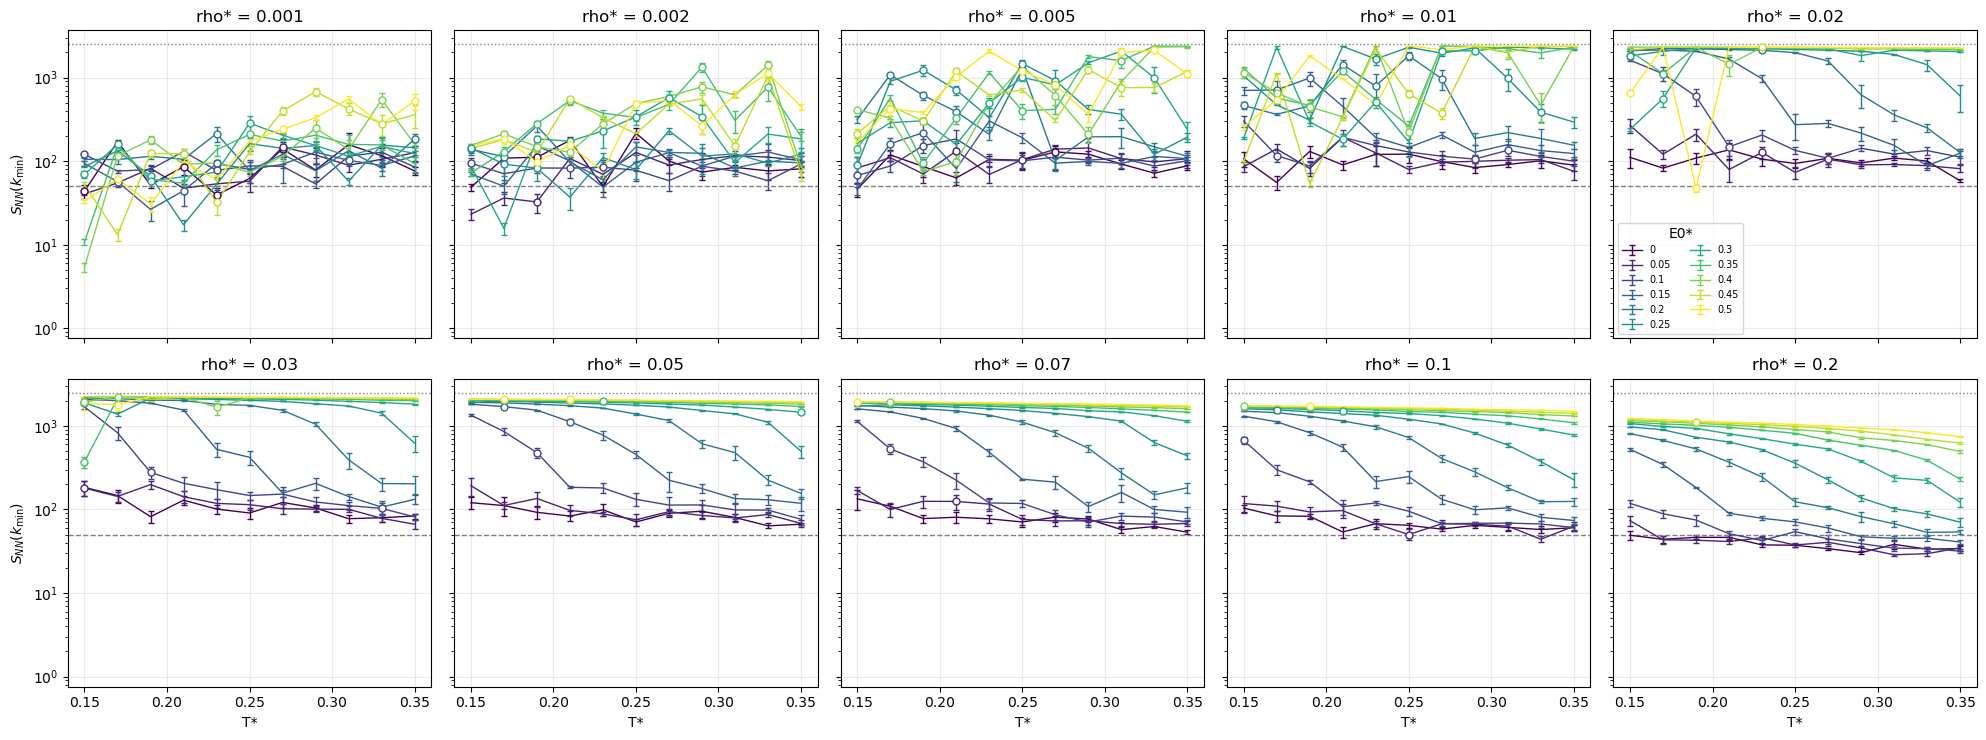

In [2]:
cmap = plt.get_cmap('viridis')
fig, axes = plt.subplots(2, 5, figsize=(20, 7.5), sharex=True, sharey=True)
for ax, rho in zip(axes.flat, RHO):
    for i, e0 in enumerate(E0):
        d = kmin[(kmin.rho_star == rho) & (kmin.E0_star == e0)].sort_values('T_star')
        c = cmap(i / (len(E0) - 1))
        ax.errorbar(d.T_star, d.S_NN, yerr=d.S_NN_sem, color=c, lw=1, capsize=2, label=f'{e0:g}')
        ax.scatter(d.T_star[d.drifting], d.S_NN[d.drifting], facecolors='white', edgecolors=c, zorder=3, s=25)
    ax.axhline(N, color='gray', ls='--', lw=1); ax.axhline(N**2, color='gray', ls=':', lw=1)
    ax.set(yscale='log', title=f'rho* = {rho:g}'); ax.grid(alpha=0.25)
for ax in axes[1]: ax.set_xlabel('T*')
for ax in axes[:, 0]: ax.set_ylabel(r'$S_{NN}(k_{\min})$')
axes[0, -1].legend(title='E0*', fontsize=7, ncol=2)
fig.tight_layout(); plt.show()

## 2. Heatmaps on the (T*, E0*) plane, one per density
Color: S_NN(k_min) on a log scale (N = uniform, N² = one cluster). × = drifting run. White contour: S_NN = CLUSTER_FACTOR·N.

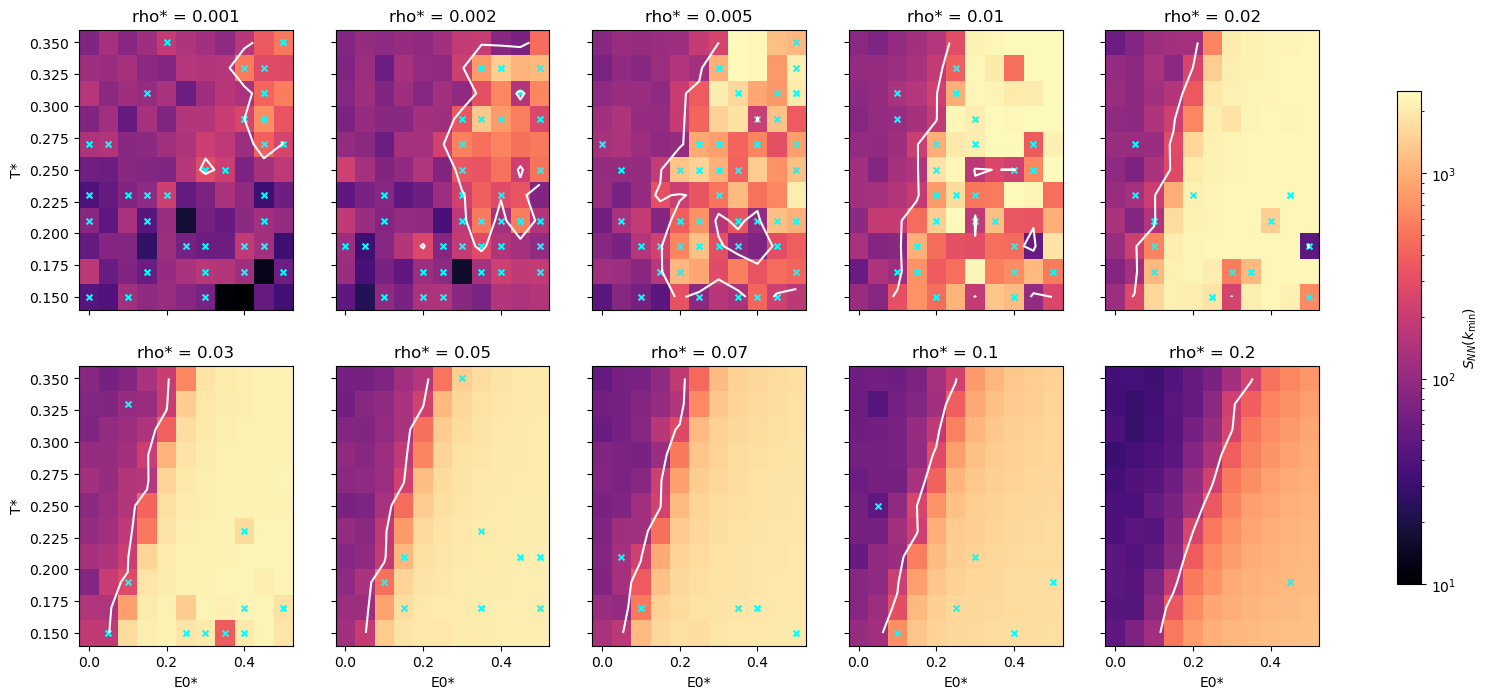

In [3]:
def grid(df, rows, cols, rkey, ckey, value):
    return df.pivot_table(index=rkey, columns=ckey, values=value).reindex(index=rows, columns=cols).to_numpy()

norm = LogNorm(vmin=N / 5, vmax=N**2)
fig, axes = plt.subplots(2, 5, figsize=(20, 8), sharex=True, sharey=True)
for ax, rho in zip(axes.flat, RHO):
    d = kmin[kmin.rho_star == rho]
    Z = grid(d, T, E0, 'T_star', 'E0_star', 'S_NN')
    im = ax.pcolormesh(E0, T, Z, norm=norm, cmap='magma', shading='nearest')
    ax.contour(E0, T, Z, levels=[CLUSTER_FACTOR * N], colors='white', linewidths=1.5)
    dr = d[d.drifting]; ax.scatter(dr.E0_star, dr.T_star, marker='x', color='cyan', s=18)
    ax.set_title(f'rho* = {rho:g}')
for ax in axes[1]: ax.set_xlabel('E0*')
for ax in axes[:, 0]: ax.set_ylabel('T*')
fig.colorbar(im, ax=axes, label=r'$S_{NN}(k_{\min})$', shrink=0.8)
plt.show()

## 3. Heatmaps on the (rho*, T*) plane, one per E0* (phase-diagram view)

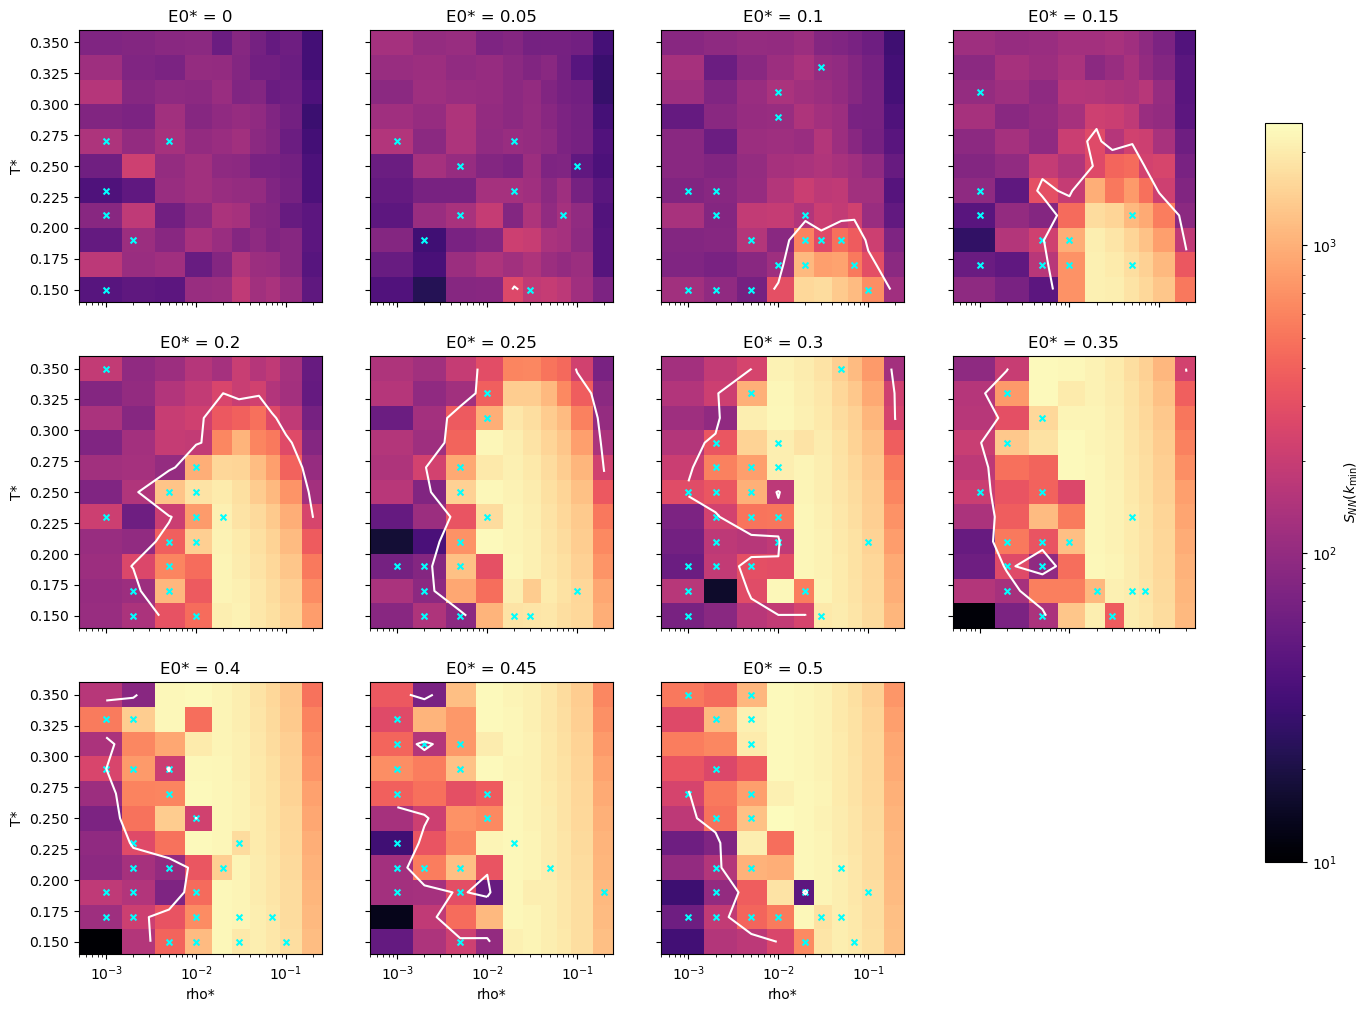

In [4]:
fig, axes = plt.subplots(3, 4, figsize=(18, 12), sharex=True, sharey=True)
for ax, e0 in zip(axes.flat, E0):
    d = kmin[kmin.E0_star == e0]
    Z = grid(d, T, RHO, 'T_star', 'rho_star', 'S_NN')
    im = ax.pcolormesh(RHO, T, Z, norm=norm, cmap='magma', shading='nearest')
    ax.contour(RHO, T, Z, levels=[CLUSTER_FACTOR * N], colors='white', linewidths=1.5)
    dr = d[d.drifting]; ax.scatter(dr.rho_star, dr.T_star, marker='x', color='cyan', s=18)
    ax.set(xscale='log', title=f'E0* = {e0:g}')
axes.flat[-1].axis('off')
for ax in axes[-1]: ax.set_xlabel('rho*')
for ax in axes[:, 0]: ax.set_ylabel('T*')
fig.colorbar(im, ax=axes, label=r'$S_{NN}(k_{\min})$', shrink=0.8)
plt.show()

## 4. Full S_NN(k) vs kσ for selected states
A droplet shows a steep rise toward small k (Porod ~k⁻³); a uniform gas stays near N.

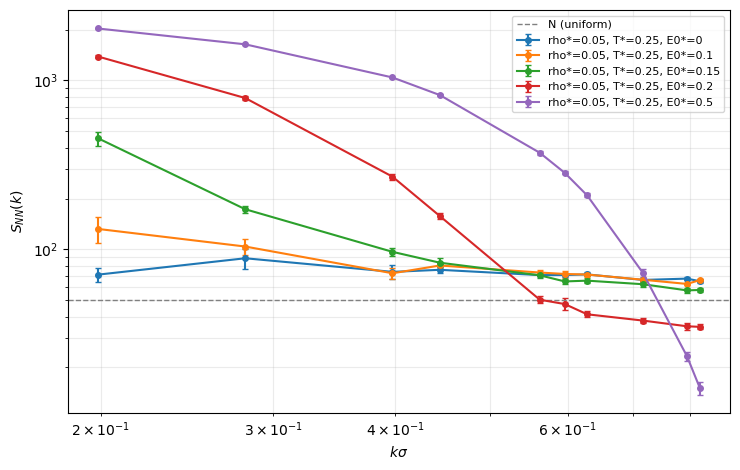

In [5]:
SELECTED = [  # (rho*, T*, E0*) -- edit freely
    (0.05, 0.25, 0.0), (0.05, 0.25, 0.1), (0.05, 0.25, 0.15), (0.05, 0.25, 0.2), (0.05, 0.25, 0.5),
]
fig, ax = plt.subplots(figsize=(7.5, 4.8))
for rho, t, e0 in SELECTED:
    d = table[np.isclose(table.rho_star, rho) & np.isclose(table.T_star, t) & np.isclose(table.E0_star, e0)]
    ax.errorbar(d.k_sigma, d.S_NN, yerr=d.S_NN_sem, marker='o', ms=4, capsize=2,
                label=f'rho*={rho:g}, T*={t:g}, E0*={e0:g}')
ax.axhline(N, color='gray', ls='--', lw=1, label='N (uniform)')
ax.set(xscale='log', yscale='log', xlabel=r'$k\sigma$', ylabel=r'$S_{NN}(k)$')
ax.grid(alpha=0.25, which='both'); ax.legend(fontsize=8); fig.tight_layout(); plt.show()

## 4b. S_NN(k) vs kσ for every ρ*, at one fixed T*
One panel per ρ*, one curve per E0* (same colors as section 1). Open markers: run drifting at k_min. All panels share axes; each density only reaches kσ from 2π√(ρ*/N) to about 4× that.

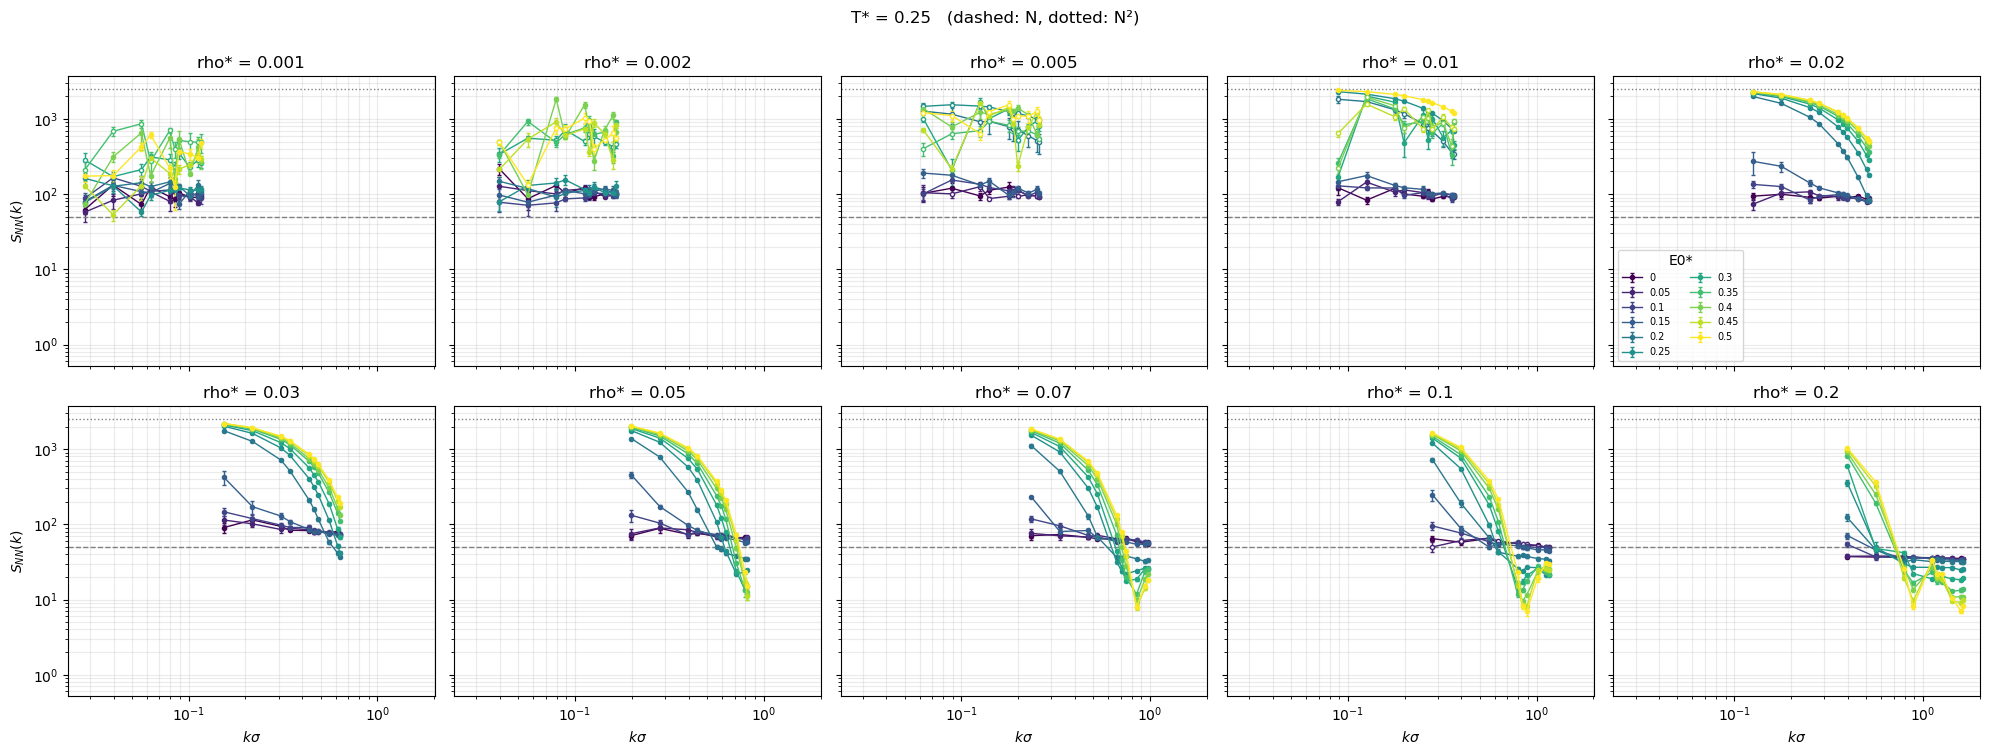

In [6]:
T_FIXED = 0.25          # choose any grid value: 0.15, 0.17, ..., 0.35
cmap = plt.get_cmap('viridis')
fig, axes = plt.subplots(2, 5, figsize=(20, 7.5), sharex=True, sharey=True)
for ax, rho in zip(axes.flat, RHO):
    for i, e0 in enumerate(E0):
        d = table[np.isclose(table.rho_star, rho) & np.isclose(table.T_star, T_FIXED)
                  & np.isclose(table.E0_star, e0)].sort_values('m2')
        c = cmap(i / (len(E0) - 1))
        drifting = abs(d.S_NN_drift_z.iloc[0]) > DRIFT_Z
        ax.errorbar(d.k_sigma, d.S_NN, yerr=d.S_NN_sem, color=c, lw=1, ms=3, capsize=1.5,
                    marker='o', mfc='white' if drifting else c, label=f'{e0:g}')
    ax.axhline(N, color='gray', ls='--', lw=1); ax.axhline(N**2, color='gray', ls=':', lw=1)
    ax.set(xscale='log', yscale='log', title=f'rho* = {rho:g}')
    ax.grid(alpha=0.25, which='both')
for ax in axes[1]: ax.set_xlabel(r'$k\sigma$')
for ax in axes[:, 0]: ax.set_ylabel(r'$S_{NN}(k)$')
axes[0, -1].legend(title='E0*', fontsize=7, ncol=2)
fig.suptitle(f'T* = {T_FIXED:g}   (dashed: N, dotted: N²)', y=1.0)
fig.tight_layout(); plt.show()

## 4c. S_NN(k) vs kσ for every ρ* on one plot, at fixed (T*, E0*)
Shows how the same attraction acts at different densities. Together the densities span kσ ≈ 0.03–1.6.

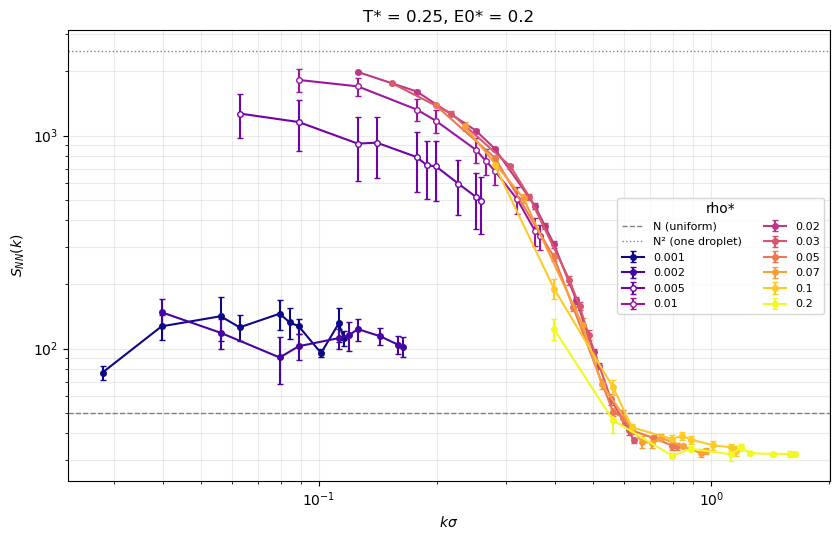

In [7]:
T_FIXED_C, E0_FIXED_C = 0.25, 0.2
cmap_r = plt.get_cmap('plasma')
fig, ax = plt.subplots(figsize=(8.5, 5.5))
for i, rho in enumerate(RHO):
    d = table[np.isclose(table.rho_star, rho) & np.isclose(table.T_star, T_FIXED_C)
              & np.isclose(table.E0_star, E0_FIXED_C)].sort_values('m2')
    c = cmap_r(i / (len(RHO) - 1))
    drifting = abs(d.S_NN_drift_z.iloc[0]) > DRIFT_Z
    ax.errorbar(d.k_sigma, d.S_NN, yerr=d.S_NN_sem, color=c, marker='o', ms=4, capsize=2,
                mfc='white' if drifting else c, label=f'{rho:g}')
ax.axhline(N, color='gray', ls='--', lw=1, label='N (uniform)')
ax.axhline(N**2, color='gray', ls=':', lw=1, label='N² (one droplet)')
ax.set(xscale='log', yscale='log', xlabel=r'$k\sigma$', ylabel=r'$S_{NN}(k)$',
       title=f'T* = {T_FIXED_C:g}, E0* = {E0_FIXED_C:g}')
ax.grid(alpha=0.25, which='both'); ax.legend(title='rho*', fontsize=8, ncol=2)
fig.tight_layout(); plt.show()

## 5. MC-time series of S_NN(k_min) (equilibration check)
Local moves equilibrate droplets slowly; a trend here means the run is not stationary.

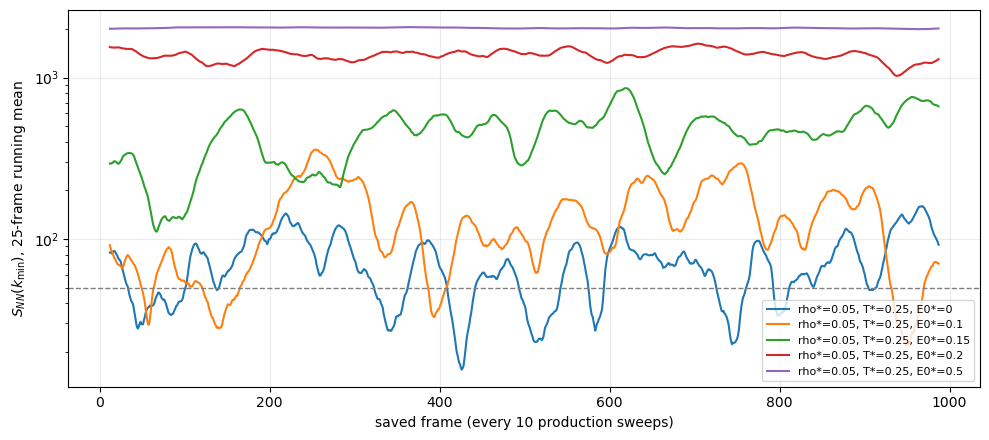

In [8]:
def state_id_of(rho, t, e0):
    d = kmin[np.isclose(kmin.rho_star, rho) & np.isclose(kmin.T_star, t) & np.isclose(kmin.E0_star, e0)]
    return int(d.state_id.iloc[0])

index = {s: i for i, s in enumerate(series['state_id'])}
window = 25
fig, ax = plt.subplots(figsize=(10, 4.5))
for rho, t, e0 in SELECTED:
    y = series['S_NN'][index[state_id_of(rho, t, e0)]]
    smooth = np.convolve(y, np.ones(window) / window, mode='valid')
    ax.plot(np.arange(len(smooth)) + window // 2, smooth, label=f'rho*={rho:g}, T*={t:g}, E0*={e0:g}')
ax.axhline(N, color='gray', ls='--', lw=1)
ax.set(yscale='log', xlabel='saved frame (every 10 production sweeps)',
       ylabel=rf'$S_{{NN}}(k_{{\min}})$, {window}-frame running mean')
ax.grid(alpha=0.25); ax.legend(fontsize=8); fig.tight_layout(); plt.show()

## 6. Summary table: clustered and drifting states

In [9]:
summary = (kmin.groupby('rho_star')
           .agg(states=('state_id', 'size'), clustered=('clustered', 'sum'),
                drifting=('drifting', 'sum'),
                clustered_and_drifting=('clustered', lambda s: (s & kmin.loc[s.index, 'drifting']).sum()),
                max_S_NN=('S_NN', 'max')))
summary['max_S_NN_over_N2'] = summary.max_S_NN / N**2
display(summary)

# Lowest E0* that clusters at each (rho*, T*) -- rough onset line
onset = (kmin[kmin.clustered & ~kmin.drifting].groupby(['rho_star', 'T_star']).E0_star.min()
         .unstack('rho_star').reindex(index=T))
display(onset)

,states,clustered,drifting,clustered_and_drifting,max_S_NN,max_S_NN_over_N2
rho_star,,,,,,
0.001,121,11,33,7,678.084248,0.271234
0.002,121,29,35,14,1405.293748,0.562117
0.005,121,59,42,29,2379.494313,0.951798
0.010,121,72,25,20,2400.855135,0.960342
0.020,121,85,13,9,2322.770976,0.929108
0.030,121,84,10,8,2243.016543,0.897207
0.050,121,84,9,9,2084.875555,0.833950
0.070,121,83,5,4,1946.433674,0.778573
0.100,121,79,6,5,1744.240398,0.697696


rho_star,0.001,0.002,0.005,0.010,0.020,0.030,0.050,0.070,0.100,0.200
T_star,,,,,,,,,,
0.15,NaN,NaN,0.20,0.10,0.05,0.10,0.10,0.10,0.15,0.15
0.17,NaN,NaN,0.25,0.20,0.15,0.10,0.10,0.15,0.10,0.15
0.19,NaN,0.20,0.50,0.20,0.15,0.15,0.15,0.10,0.15,0.20
0.21,NaN,NaN,NaN,0.15,0.15,0.15,0.20,0.15,0.15,0.20
0.23,NaN,0.35,0.15,0.35,0.15,0.15,0.15,0.15,0.20,0.25
0.25,NaN,0.35,0.40,0.25,0.15,0.15,0.15,0.20,0.20,0.25
0.27,NaN,0.35,0.35,0.25,0.15,0.20,0.20,0.20,0.20,0.30
0.29,0.50,0.45,0.25,0.25,0.20,0.20,0.20,0.20,0.20,0.30
0.31,0.50,0.35,0.25,0.30,0.20,0.20,0.20,0.20,0.25,0.35
